**Lab 07 CNN Architecture**

Instructor Name: Attique-ur-Rehman

Student Name: Fatima Kashif

Sap Id: 70177832

In [2]:
import numpy as np

image = np.array([[3, 1, 0, 2, 1],
                  [2, 0, 1, 3, 0],
                  [4, 1, 0, 1, 2],
                  [1, 3, 2, 0, 1],
                  [0, 2, 1, 4, 2]])

kernel = np.array([[1, 0, -1],
                   [1, 0, -1],
                   [1, 0, -1]])

print(image)
print(kernel)

[[3 1 0 2 1]
 [2 0 1 3 0]
 [4 1 0 1 2]
 [1 3 2 0 1]
 [0 2 1 4 2]]
[[ 1  0 -1]
 [ 1  0 -1]
 [ 1  0 -1]]


In [3]:
feature_map = np.zeros((3, 3))
for i in range(3):
    for j in range(3):
        window = image[i:i+3, j:j+3]
        feature_map[i, j] = np.sum(window * kernel)

print(feature_map)

[[ 8. -4. -2.]
 [ 4.  0.  0.]
 [ 2.  1. -2.]]


In [4]:
relu = np.maximum(0, feature_map)
print(relu)

[[8. 0. 0.]
 [4. 0. 0.]
 [2. 1. 0.]]


In [5]:
pooled = np.zeros((2, 2))
for i in range(2):
    for j in range(2):
        pooled[i, j] = np.max(relu[i:i+2, j:j+2])

print(pooled)

[[8. 0.]
 [4. 1.]]


In [6]:
flat = pooled.flatten()
print("Flattened:", flat)

cat_score  = 8*0.3 + 0*0.1 + 4*0.2 + 1*0.1
dog_score  = 1.5
bird_score = 0.6
scores = np.array([cat_score, dog_score, bird_score])
print("Scores:", scores)

Flattened: [8. 0. 4. 1.]
Scores: [3.3 1.5 0.6]


In [7]:
probs = np.exp(scores) / np.sum(np.exp(scores))

for name, p in zip(["Cat", "Dog", "Bird"], probs):
    print(f"{name}: {p*100:.0f}%")

Cat: 81%
Dog: 13%
Bird: 5%


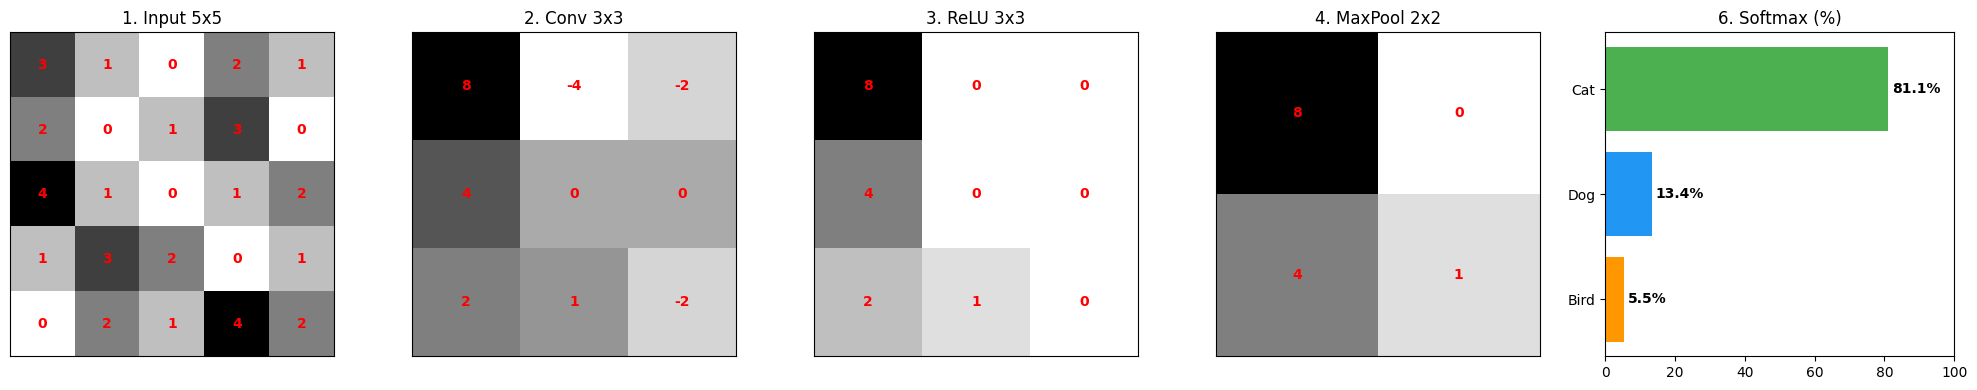

In [8]:
import matplotlib.pyplot as plt

classes = ["Cat", "Dog", "Bird"]

fig, ax = plt.subplots(1, 5, figsize=(20, 4))
stages = [(image, "1. Input 5x5"), (feature_map, "2. Conv 3x3"),
          (relu, "3. ReLU 3x3"), (pooled, "4. MaxPool 2x2")]

for a, (m, title) in zip(ax[:4], stages):
    a.imshow(m, cmap="gray_r")
    a.set_title(title)
    for (i, j), v in np.ndenumerate(m):
        a.text(j, i, f"{int(v)}", ha="center", va="center", color="red", weight="bold")
    a.set_xticks([]); a.set_yticks([])

ax[4].barh(classes, probs * 100, color=["#4CAF50", "#2196F3", "#FF9800"])
ax[4].set_xlim(0, 100)
ax[4].invert_yaxis()
ax[4].set_title("6. Softmax (%)")
for k, v in enumerate(probs * 100):
    ax[4].text(v + 1, k, f"{v:.1f}%", va="center", weight="bold")

plt.tight_layout()
plt.show()